In [1]:
import sys, os, datetime, importlib

import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
import tqdm

import nn_reg; importlib.reload(nn_reg)
import nn_tf; importlib.reload(nn_tf)

<module 'nn_tf' from '/mnt/c/Users/user/Desktop/rnd/AISat/VolumeInversion/nn_tf.py'>

In [2]:
import PyPreprocess_Single
import util_collector
import brack2bing
import os, math

#import util_filters; importlib.reload(util_filters)

import script_CoreExplorer; importlib.reload(script_CoreExplorer)
import data_aosi; importlib.reload(data_aosi)
import data_cryos; importlib.reload(data_cryos)

'''targets = [
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP126061420-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP067871340-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP167051410-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP169531410-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP171281410-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP171281420-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP173761410-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP173761420-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP176241410-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP177991410-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP178721410-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP200601420-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP202351420-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP059691420-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP062171410-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP072381420-L1.1_cache',
    '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP094991420-L1.1_cache'
]'''
ddir = '/mnt/d/ALOS1-Landfast/BeaufortSouth'
targets = [os.path.join(ddir, el) for el in os.listdir(ddir) if '.zip' not in el]
fn_ = 'em_resice.hdf5'
feed, floqs, vl, data_shapes = script_CoreExplorer.get_core(fn_, 100);



In [249]:
targets[11]

'/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP167051410-L1.1_cache'

In [3]:
#model = nn_tf.r2PA_CSDE_Transformer(h=16, dim=feed.shape[-1], hdim=32, c=1, activation='sigmoid', sigmas=etas).to('cuda', torch.float32)
#model.load_state_dict(torch.load('260812_DiffusionBlock_epoch500_t32h16d32_RESICE_dict.pth'))
#torch.save(model.state_dict(), '260812_DiffusionBlock_epoch500_t32h16d32_RESICE_dict.pth')

#torch.save(model, '260815_DiffusionBlock_epoch500_t128h8d16_RESICE.pth')
#torch.save(model, '260815_DiffusionBlock_langevin0.05_epoch500_t128h8d16_RESICE.pth')
#torch.save(model, '260815_DiffusionBlock_epoch0_500_t64h12d16_RANDOMS_epoch500_2000_RESICE100.pth')

#torch.save(model, '260812_DiffusionBlock_epoch500_t64h12d16_RESICE.pth')
#torch.save(model, '260812_DiffusionBlock_epoch1000_t32h16d32_RESICE.pth')
# 260806_DiffusionBlock_500d32h16l32_RESICE.pth.. 0730_DiffusionBlock_5k_1_.pth
#torch.save(model, '260806_DiffusionBlock_500d32h16l32_RESICE.pth')
#torch.save(model.state_dict(), '260806_DiffusionBlock_500d32h16l32_RESICE_dict.pth')
#model2 = torch.load('260806_DiffusionBlock_500d32h16l32_RESICE.pth', weights_only=False)
#model = torch.load('260812_DiffusionBlock_epoch500_t64h12d16_RESICE.pth', weights_only=False)
#model = torch.load('260815_DiffusionBlock_epoch500_t128h8d16_RESICE.pth', weights_only=False)
model = torch.load('260815_DiffusionBlock_langevin0.05_epoch500_t128h8d16_RESICE.pth', weights_only=False)
#model = torch.load('260815_DiffusionBlock_epoch500_t64h12d16_RANDOMS.pth', weights_only=False)

whitener = model.whitener
dwhitenr = model.unwhitener

In [4]:
#model.whitener = nn_reg.FixedRescaler(feed)
#model.unwhitener = nn_reg.FixedDescaler(model.whitener)
#torch.save(model, '260815_DiffusionBlock_langevin0.05_epoch500_t128h8d16_RESICE.pth')
slc_ds = PyPreprocess_Single.Dataset_SNAPbase(cache_dir=targets[11])
#dir(PyPreprocess_Single)

#whitenr = nn_reg.FixedDescaler(nn_reg.FixedRescaler(feed))
#plt.plot(model.unwhitener(torch.zeros(1,1,462).cuda())[0,0,:90].cpu())

located cache at /mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP167051410-L1.1_cache
extracting parameters...
retrieved metadata.
retrieved SLC complex (B,H,W).
rescaling auxiliary data...
converted incidence angle from degrees to radians.
all parameters extracted.
dataset loaded.


In [5]:
importlib.reload(script_CoreExplorer)
outputs = script_CoreExplorer.analyze_image(
    targets[11],
    model, vl, floqs,
    slc_ds, rmask_fn='mask_bisplit.png', sr=16, hist_bins=20, valids=['AMSR_KH', 'SMOS', 'neXtSIM', 'IC1'],
    aspect=4
)

 75%|███████████████████████████████████████████████████████████████▊                     | 6/8 [00:06<00:02,  1.01s/it]


retrieving validation data for date 20090314
retrieving AMSR_KH data...
retrieving SMOS data...
could not access dataset (error : [Errno 2] No such file or directory: '/mnt/d/UBremen_SeaIce_Data/SMOS_SIT/20090314_hvnorth_rfi_l1c.nc')
retrieving neXtSIM data...
retrieving IC1 data...
could not access dataset (error : input date not within dataset bounds)
data retrieved.


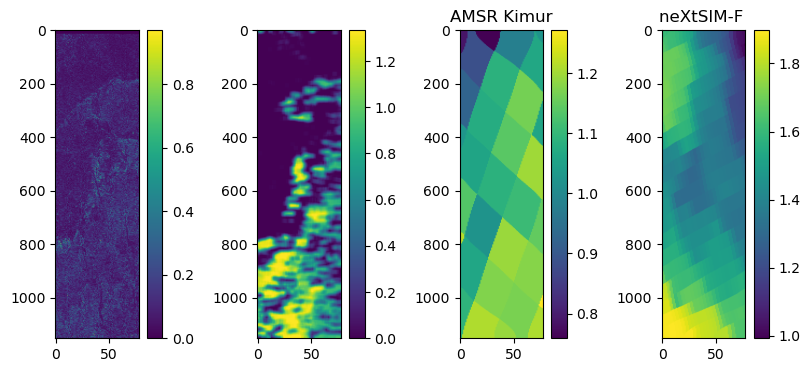

[22.19 28.16 34.5  41.36 49.04 58.17]


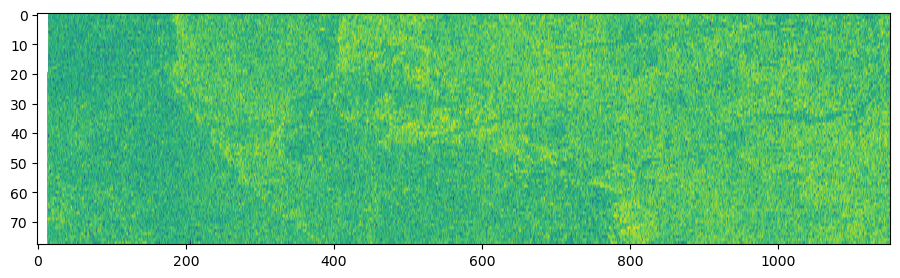

In [6]:
plt.figure(figsize=(10,4))
sr = 16
plt.subplot(1,4,1); plt.imshow(torch.as_tensor(slc_ds.slc[0,::sr,::sr]).abs(), aspect=0.25); plt.colorbar()
plt.subplot(1,4,2); plt.imshow(outputs[0].cpu(), aspect=0.25); plt.colorbar()
for i in range(len(outputs[1])):
    plt.subplot(1,4,i+3); plt.imshow(outputs[1][list(outputs[1].keys())[i]], aspect=0.25)
    plt.title(list(outputs[1].keys())[i][:10]); plt.colorbar()
plt.show()
plt.figure(figsize=(12,3)); plt.imshow(torch.as_tensor(slc_ds.slc[0,::sr,::sr]).T.flip(dims=(0,)).abs().log(), aspect=4)
#plt.figure(figsize=(12,3)); plt.imshow(torch.as_tensor(np.rad2deg(slc_ds.ia[::8,::8]).T), aspect=4); plt.colorbar()
print(floqs)

feed vector length: 462


Text(0.5, 1.0, 'whitened SLC-C4 zero-vector input')

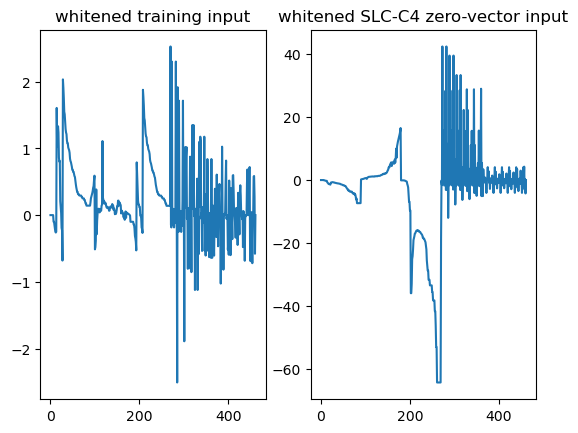

In [61]:
print('feed vector length:', feed[0].shape[-1])
plt.subplot(1,2,1); plt.plot(whitener(feed[0])[0,0].cpu()); plt.title('whitened training input');
tmp = script_CoreExplorer.slc2core(torch.as_tensor(slc_ds.slc[:,::sr,::sr]).cuda().moveaxis(0,-1),
                                   torch.as_tensor(slc_ds.ia[::sr,::sr]).cuda(), 270, whitener, floqs)[0][10300] * 1000
plt.subplot(1,2,2); plt.plot(tmp[0].cpu()); plt.title('whitened SLC-C4 zero-vector input')

In [45]:
tmp[10000]

tensor([[ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00, -9.9742e-05, -9.9449e-05, -1.5501e-04,
         -2.0168e-04, -2.4909e-04, -2.6058e-04, -2.4912e-04, -7.1635e-04,
         -8.5832e-04, -1.0220e-03, -1.2467e-03, -1.2812e-03, -1.3145e-03,
         -1.3656e-03, -1.4539e-03, -8.1186e-04, -8.1279e-04, -7.5324e-04,
         -6.7638e-04, -6.8307e-04, -6.8079e-04, -7.5035e-04, -7.7012e-04,
         -7.8443e-04, -8.6377e-04, -8.7113e-04, -9.0506e-04, -9.6370e-04,
         -9.7991e-04, -9.8515e-04, -1.0398e-03, -1.0823e-03, -1.0835e-03,
         -1.1331e-03, -1.1476e-03, -1.1604e-03, -1.1997e-03, -1.3193e-03,
         -1.3737e-03, -1.3879e-03, -1.4470e-03, -1.5126e-03, -1.6277e-03,
         -1.6130e-03, -1.7077e-03, -1.6822e-03, -1.7921e-03, -1.9067e-03,
         -1.9014e-03, -2.1229e-03, -2.3141e-03, -2.5124e-03, -2.7399e-03,
         -3.0245e-03, -3.0163e-03, -3.4147e-03, -3.4179e-03, -3.3963e-03,
         -3.6871e-03, -3.7070e-03, -3.

In [35]:
a, b = (slc_ds.slc[None,:,::sr,::sr], slc_ds.ia[::sr,::sr])
a.shape[2:] == b.shape

True

In [262]:
#plt.hist(outputs[0].cpu().flatten(), bins=100); plt.show()
#plt.hist(list(outputs[1].values())[1].flatten(), bins=100); plt.show()

torch.Size([1, 1, 1, 1, 90]) torch.Size([1, 1, 1, 90]) torch.Size([1, 1, 1, 30, 90])
torch.Size([1, 1, 1, 1, 90]) torch.Size([1, 1, 1, 90]) torch.Size([1, 1, 1, 30, 90])


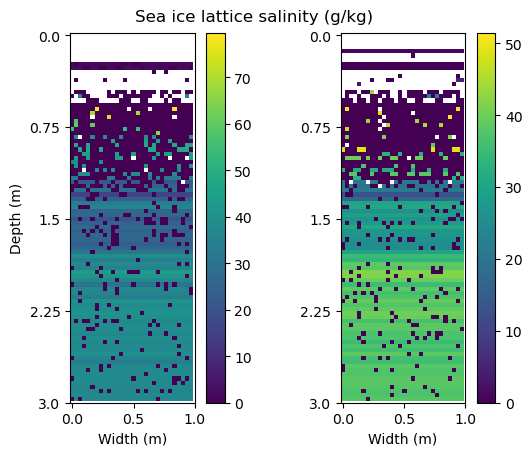

In [279]:
#item = slc_ds.slc[0,::16,::16]; item[item==0] = np.nan
#plt.imshow(np.abs(item).T, aspect=_aspect)
icesim = script_CoreExplorer._get_ltsolvr()

S, T, rho = (outputs[-1][0])[:,0,:sum(vl[:3])].cuda().reshape(3, 1, -1)
samp = icesim.gen_lattice(T,S,rho,(1,30))[0,0,1,1:-1,1:-1].cpu()
plt.suptitle('Sea ice lattice salinity (g/kg)', y=0.93)
plt.subplot(1,2,1);# plt.imshow(np.array([(samp > 0), (samp < 0), samp == 0]).swapaxes(-1,0).astype(float))
samp[samp < 0] = torch.nan; plt.imshow(samp.T); plt.colorbar()
plt.yticks(np.linspace(0,90,5), np.linspace(0,3,5)); plt.ylabel('Depth (m)')
plt.xticks(np.linspace(0,30,3), np.linspace(0,1,3)); plt.xlabel('Width (m)')

S, T, rho = (outputs[-1][1])[:,0,:sum(vl[:3])].cuda().reshape(3, 1, -1)
samp = icesim.gen_lattice(T,S,rho,(1,30))[0,0,1,1:-1,1:-1].cpu()
plt.subplot(1,2,2);# plt.imshow(np.array([(samp > 0), (samp < 0), samp == 0]).swapaxes(-1,0).astype(float))
samp[samp < 0] = torch.nan; plt.imshow(samp.T); plt.colorbar()
plt.yticks(np.linspace(0,90,5), np.linspace(0,3,5)); #plt.ylabel('Depth (m)')
plt.xticks(np.linspace(0,30,3), np.linspace(0,1,3)); plt.xlabel('Width (m)')

plt.savefig('figure.png')
#plt.show()

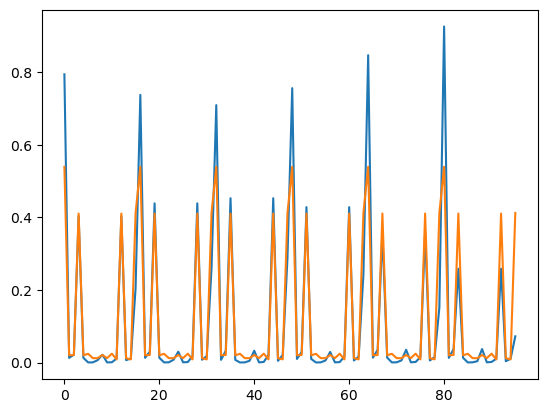

In [206]:
import util_filters
#slc = torch.as_tensor(slc_ds.slc[:,::8,::8]).permute(1,2,0)
#slc = util_filters.nanpute_n1mean(slc, 200, (0, 1))
if False:
    C4 = slc[...,:,None] * slc[...,None,:].conj() # construct normalized C4
    C4 = torch.complex(
        F.avg_pool2d(C4.real.permute(2,3,0,1), (11,11), stride=1, padding=5, count_include_pad=False).permute(2,3,0,1),
        F.avg_pool2d(C4.imag.permute(2,3,0,1), (11,11), stride=1, padding=5, count_include_pad=False).permute(2,3,0,1)
    )
    C4 = C4 / torch.diagonal(C4, 0, -2, -1).sum(dim=-1)[...,None,None] # H,W,B,B
    
    #feed, floqs, vl, data_shapes = script_CoreExplorer.get_core('em_resice.hdf5', 103, whitener=whitener);
    tmp = model.unwhitener(feed)[:,0,-sum(vl[-2:]):].view(-1,2,96)
    tmp = torch.complex(tmp[:,0], tmp[:,1]).reshape(-1,6,4,4).reshape(-1,96)
    plt.plot(tmp[50].abs().cpu())
    
    # ...
    tmpp = C4.reshape(-1,1,16).expand(-1,6,16).reshape(-1,96)
    tmpp = torch.cat([torch.zeros(tmpp.shape[0], 270), tmpp.real, tmpp.imag], dim=1).cuda()
    tmpp = tmpp[:,None,]#model.whitener((tmpp[:,None,])) / 1
    tmpp = torch.complex(tmpp[:,:,270:366], tmpp[:,:,366:])
    
    plt.plot(tmpp[100000,0].abs().cpu()); plt.show()#/np.linspace(1000,250,96))

    tmp = tmp.cpu()
    tmpp = tmpp.cpu()
    
    plt.title(f'Average normalized covariances at {floqs[0]} degrees incidence')
    plt.plot(tmp[:,:16].mean(0).abs().cpu())
    plt.plot(tmpp[:,0,:16].mean(0).abs().cpu())
    plt.yscale('log');# plt.ylabel()
    plt.xticks(np.arange(16), np.array([[f'nC{i+1}{j+1}' for j in range(4)] for i in range(4)]).flatten(), rotation=45)
    plt.legend(['RESICE simulated', 'ALOS-1 SLC ALPSRP059691420 (Beaufort Sea)'])
    
    plt.show()

NameError: name 'sit_est' is not defined

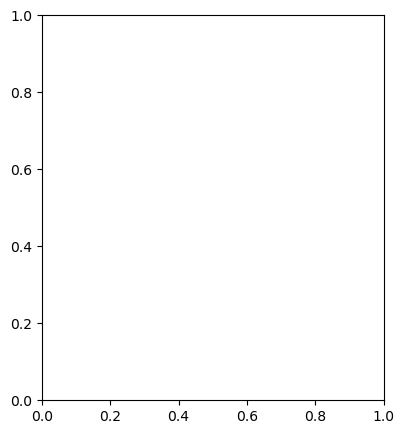

In [16]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.hist([sit_est[mask_bisplit[::8,::8,0][:2290]], sit_est[~mask_bisplit[::8,::8,0][:2290]]], bins=20); plt.yscale('log')
#plt.hist([sit_est[mask_bisplit[::8,::8,0][:2290]], outputs[0][~mask_bisplit[::8,::8,0]]], bins=20); plt.yscale('log')
plt.legend(['region 1', 'region 2']); plt.title('IceMatcher pixelwise'); plt.xlabel('Sea ice thickness (m)'); plt.ylabel('Pixels')

plt.subplot(1,3,2)
plt.hist([outputs[1][mask_bisplit[::8,::8,0]], outputs[1][~mask_bisplit[::8,::8,0]]], bins=20); plt.yscale('log')
plt.legend(['region 1', 'region 2']); plt.title('AMSR_KimuraHasumi 10x10 km'); plt.xlabel('Sea ice thickness (m)'); plt.ylabel('Pixels')

plt.subplot(1,3,3)
plt.hist([outputs[2][0,0,mask_bisplit[::8,::8,0]], outputs[2][0,0,~mask_bisplit[::8,::8,0]]], bins=20); plt.yscale('log')
plt.legend(['region 1', 'region 2']); plt.title('Arctic Sea Ice Reanalysis 3x3 km'); plt.xlabel('Sea ice thickness (m)'); plt.ylabel('Pixels')

plt.show()